# Distribuição dos produtos — Etapa 1 do plano de previsão

**Objetivo:** conhecer as séries produto × loja antes de prever qualquer coisa, e dividi-las em grupos que se comportam de forma parecida.

Cada grupo recebe um tratamento diferente nas próximas etapas:

| Etapa | Como usa os grupos deste notebook |
|---|---|
| 2 — Baselines (médias móveis) | Mede o erro de cada baseline **por grupo** e define quem recebe baseline e quem recebe regra própria |
| 3 — Engenharia de features | Os grupos viram features (classe ABC, frequência, fase de vida) |
| 4 — Modelo | O resultado é comparado com a melhor baseline de cada grupo |

**Resposta curta:** as séries formam uma grade quase completa (todo produto vendendo em quase todos os locais), com histórico de vários anos, e se comportam de forma parecida entre si. Não há produtos novos nem produtos descontinuados de verdade, o volume é espalhado (sem "campeões de venda" isolados), todas as categorias seguem a mesma estação e a demanda está crescendo. **Todas as séries entram juntas no mesmo modelo**, sem regra especial por tipo de produto.

**Em palavras simples:** este notebook é um "raio-x" do negócio antes de montar qualquer previsão. As perguntas são práticas: existe um produto que domina as vendas? Existem produtos "novos" sem histórico? Existem produtos "mortos" que nunca mais vão vender? Cada categoria vende mais forte em épocas diferentes do ano? A resposta para quase tudo aqui é "não, é tudo bem parecido e regular" — o que é bom, porque significa que dá para tratar todas as séries produto × loja da mesma forma.

**Base:** demanda mensal, só com meses completos. As janelas de 12 meses terminam no **mês de referência**: o último mês completo do dataset.

**Seções:**
1. Visão geral
2. Concentração do volume (curva ABC)
3. Frequência de venda
4. Fase de vida (ativas, paradas)
5. Sazonalidade por categoria
6. Tendência
7. Alcance dos produtos
8. Resumo: grupos que seguem para a Etapa 2

Os cálculos ficam em `src/analytics_ai/eda_demand_distribution.py`.

## Setup

In [1]:
import sys
from pathlib import Path


def _find_project_root(start: Path) -> Path:
    """Sobe a partir do diretório do notebook até achar a raiz do bundle (databricks.yml)."""
    for candidate in (start, *start.parents):
        if (candidate / "databricks.yml").exists():
            return candidate
    raise FileNotFoundError(f"databricks.yml não encontrado acima de {start}")


# Funciona no workspace (.bundle/.../files/notebooks/ml) e localmente.
PROJECT_ROOT = _find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import functions as F

from src.analytics_ai.eda_demand_distribution import (
    add_abc_class,
    add_frequency_class,
    add_life_phase,
    compare_to_global_season,
    complete_months,
    pareto_points,
    product_reach,
    reference_month,
    seasonal_index_by,
    segment_summary,
    series_profile,
    year_over_year_growth,
)
from src.analytics_ai.ml_config import MlFeatureConfig

# No Databricks o notebook já expõe `spark`; localmente cria via Databricks Connect
# (defina DATABRICKS_PROFILE com o nome do seu profile em ~/.databrickscfg).
spark = globals().get("spark")
if spark is None:
    from src.ingestion.utils import build_spark_session

    spark = build_spark_session()

# Databricks e Jupyter injetam `display`; fora deles, cai para print.
display = globals().get("display", print)

plt.rcParams["figure.dpi"] = 100
CORES = ["#2E5C8A", "#E8874C", "#4C9A6A", "#B24C4C"]
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

config = MlFeatureConfig.from_environment_monthly()
DATE_COL = config.date_col

monthly = spark.table(config.source_table)
products = spark.table(config.gold_table("dim_products")).select("sk_product", "category_name", "brand_name")
locations = spark.table(config.gold_table("dim_locations")).select(
    "sk_location", "location_name", "location_type", "region"
)
global_season = spark.table(config.silver_table("int_high_season_months"))

complete = complete_months(monthly, DATE_COL).join(products, "sk_product").join(locations, "sk_location")
REF_MONTH = reference_month(complete, DATE_COL)

print(f"tabela: {config.source_table}")
print(f"mês de referência (último mês completo): {REF_MONTH}")

tabela: dev_lh_nautical.ml.agg_demand_monthly
mês de referência (último mês completo): 2026-08-01


In [3]:
profile = series_profile(monthly, REF_MONTH, DATE_COL)
segmented_local = add_life_phase(add_frequency_class(add_abc_class(profile))).toPandas()
segmented = spark.createDataFrame(segmented_local).join(products, "sk_product").join(locations, "sk_location")

print(f"{len(segmented_local)} séries produto × loja no perfil")

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


6054 séries produto × loja no perfil


## 1. Visão geral

Tamanho do universo e como o volume dos últimos 12 meses se divide entre lojas.

**O que olhar:** se uma loja ou tipo de loja concentra o volume, o erro do modelo nela pesa mais no total e vale acompanhar separado.

,series,produtos,lojas,categorias,primeiro_mes_completo,ultimo_mes_completo
0,6054,1009,6,12,2020-01-01,2026-08-01


C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


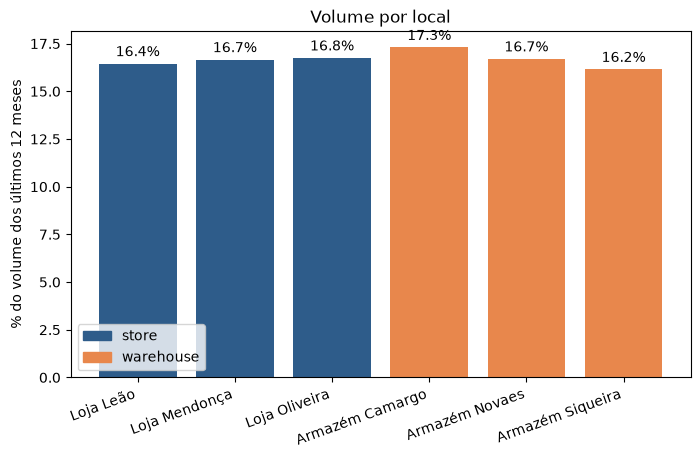

In [4]:
overview = complete.agg(
    F.countDistinct("sk_product", "sk_location").alias("series"),
    F.countDistinct("sk_product").alias("produtos"),
    F.countDistinct("sk_location").alias("lojas"),
    F.countDistinct("category_name").alias("categorias"),
    F.min(DATE_COL).alias("primeiro_mes_completo"),
    F.max(DATE_COL).alias("ultimo_mes_completo"),
).toPandas()
display(overview)

by_location = segment_summary(segmented, ["location_type", "location_name"]).toPandas()
type_colors = dict(zip(by_location["location_type"].unique(), CORES))

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    by_location["location_name"],
    by_location["share_volume_12m"] * 100,
    color=by_location["location_type"].map(type_colors),
)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylabel("% do volume dos últimos 12 meses")
ax.set_title("Volume por local")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()]
ax.legend(handles, type_colors.keys())
plt.xticks(rotation=20, ha="right")
plt.show()

**O que o gráfico mostra:** todo produto aparece em quase todos os locais, e nenhum local concentra o volume — todos ficam numa faixa parecida. Lojas e armazéns têm peso semelhante, e o tipo de local deve ajudar pouco como feature.

## 2. Concentração do volume — curva ABC

**Pergunta:** o volume está concentrado em poucas séries ou espalhado?

- **Concentrado** (ex.: 20% das séries fazem 80% do volume): o erro nas séries A decide o resultado; vale olhar essas séries com lupa.
- **Espalhado** (precisa de metade das séries ou mais para chegar a 80%): não existe um grupo pequeno que resolva o problema; o modelo precisa funcionar bem para a maioria.

**Decisão que sai daqui:** a classe ABC vira feature (Etapa 3).

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


,top_share_series,top_n_series,share_volume
0,0.05,298,0.1150
1,0.10,597,0.2075
2,0.20,1193,0.3631
3,0.50,2983,0.7111


,abc_class,n_series,volume_12m,share_series,share_volume_12m
0,A,3593,111542.0,0.5935,0.80
1,B,1378,20914.0,0.2276,0.15
2,C,995,6967.0,0.1644,0.05
3,sem_venda,88,0.0,0.0145,0.00


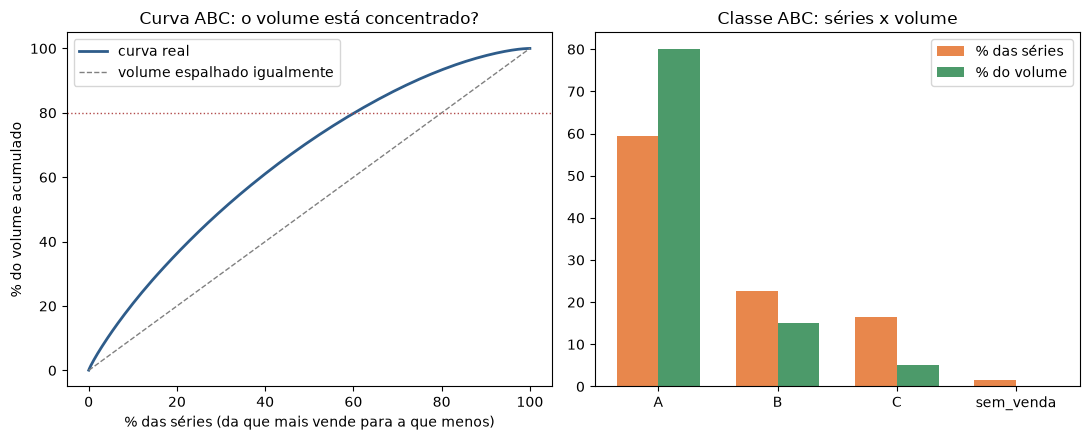

In [5]:
pareto = pareto_points(segmented.filter(F.col("volume_12m") > 0)).toPandas()
abc_summary = segment_summary(segmented, ["abc_class"]).toPandas()
display(pareto)
display(abc_summary)

# Curva de Lorenz: % acumulado de séries (da que mais vende para a que menos) x % acumulado de volume.
ranked = (
    segmented.filter(F.col("volume_12m") > 0)
    .select("volume_12m")
    .toPandas()
    .sort_values("volume_12m", ascending=False)
    .reset_index(drop=True)
)
ranked["pct_series"] = (ranked.index + 1) / len(ranked) * 100
ranked["pct_volume"] = ranked["volume_12m"].cumsum() / ranked["volume_12m"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].plot(ranked["pct_series"], ranked["pct_volume"], color=CORES[0], linewidth=2, label="curva real")
axes[0].plot([0, 100], [0, 100], color="gray", linestyle="--", linewidth=1, label="volume espalhado igualmente")
axes[0].axhline(80, color=CORES[3], linestyle=":", linewidth=1)
axes[0].set_xlabel("% das séries (da que mais vende para a que menos)")
axes[0].set_ylabel("% do volume acumulado")
axes[0].set_title("Curva ABC: o volume está concentrado?")
axes[0].legend()

x = range(len(abc_summary))
width = 0.35
axes[1].bar([i - width / 2 for i in x], abc_summary["share_series"] * 100, width, color=CORES[1], label="% das séries")
axes[1].bar([i + width / 2 for i in x], abc_summary["share_volume_12m"] * 100, width, color=CORES[2], label="% do volume")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels(abc_summary["abc_class"])
axes[1].set_title("Classe ABC: séries x volume")
axes[1].legend()

plt.tight_layout()
plt.show()

**O que o gráfico mostra:** a curva real fica bem próxima da reta de "volume espalhado igualmente" — bem longe da regra 80/20 clássica. É preciso boa parte das séries para chegar a 80% do volume, então **não existe um grupo pequeno de séries que resolva o problema**: o modelo precisa funcionar bem para a maioria, e não é preciso ponderar a avaliação por volume.

**Em palavras simples:** numa loja onde a regra 80/20 valesse, bastariam os 20% de produtos "estrela" para somar 80% da venda. Aqui, é preciso uma fatia bem maior dos produtos para chegar nesses mesmos 80% — a venda é bem repartida entre muitos produtos parecidos, sem "campeões" isolados.

## 3. Frequência de venda

**Pergunta:** em quantos dos últimos 12 meses cada série vendeu?

Isso diz quanto de informação cada média móvel tem para trabalhar: uma janela de 3 meses, numa série que vende em poucos meses do ano, alterna entre zero e picos.

**Decisão que sai daqui:** a frequência vira feature e é um dos cortes da comparação de baselines na Etapa 2.

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


,frequency_class,n_series,volume_12m,share_series,share_volume_12m
3,sem_venda,88,0.0,0.0145,0.0000
1,baixa,1607,18428.0,0.2654,0.1322
2,media,2939,68626.0,0.4855,0.4922
0,alta,1420,52369.0,0.2346,0.3756


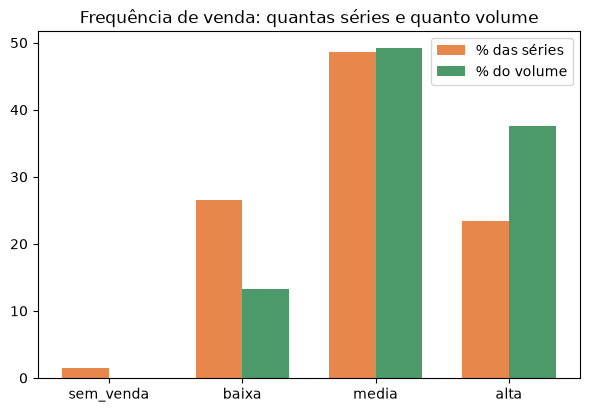

In [6]:
freq_order = ["sem_venda", "baixa", "media", "alta"]
freq_summary = segment_summary(segmented, ["frequency_class"]).toPandas()
freq_summary["frequency_class"] = pd.Categorical(freq_summary["frequency_class"], categories=freq_order, ordered=True)
freq_summary = freq_summary.sort_values("frequency_class")
display(freq_summary)

fig, ax = plt.subplots(figsize=(7, 4.5))
x = range(len(freq_summary))
width = 0.35
ax.bar([i - width / 2 for i in x], freq_summary["share_series"] * 100, width, color=CORES[1], label="% das séries")
ax.bar([i + width / 2 for i in x], freq_summary["share_volume_12m"] * 100, width, color=CORES[2], label="% do volume")
ax.set_xticks(list(x))
ax.set_xticklabels(freq_summary["frequency_class"])
ax.set_title("Frequência de venda: quantas séries e quanto volume")
ax.legend()
plt.show()

**O que o gráfico mostra:** uma série típica vende em poucos meses do ano — a maior parte cai nas classes "baixa" e "média" frequência. Numa janela de 3 meses isso é menos de um mês com venda, então uma média móvel curta vai alternar entre zero e picos na maioria das séries. A expectativa é que uma média mais longa (12 meses) se saia melhor — a Etapa 2 confirma isso.

## 4. Fase de vida

**Pergunta:** quantas séries estão ativas, quantas são novas e quantas pararam de vender?

- **Paradas** (sem venda em 12 meses): candidatas a ficar fora do treino com previsão zero por regra — só se elas **não voltarem a vender**.
- **Novas** (menos de 12 meses de histórico): a média de 12 meses ainda não fecha.

**Decisão que sai daqui:** se o modelo precisa de regras separadas para novas e paradas, ou se todas as séries entram juntas.

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


,life_phase,n_series,volume_12m,share_series,share_volume_12m
0,ativa,5966,139423.0,0.9855,1.0
1,parada,88,0.0,0.0145,0.0


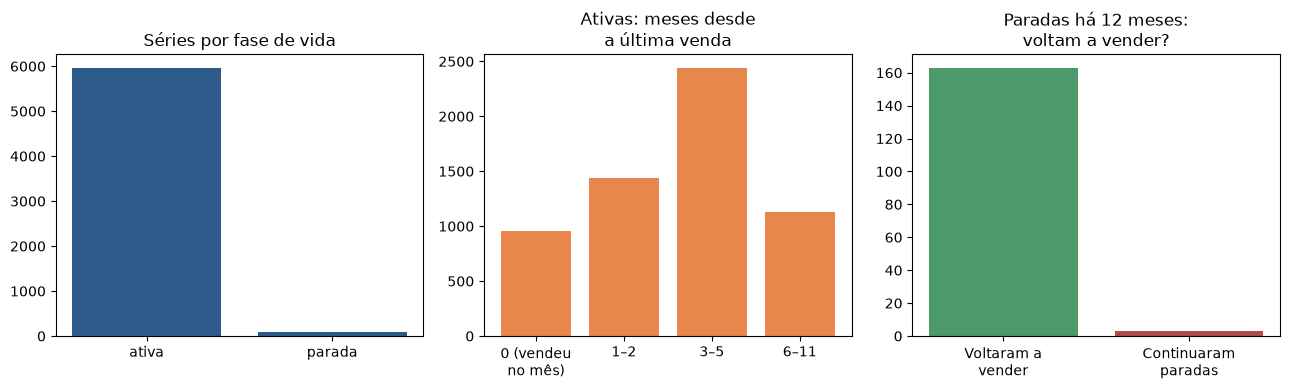

In [7]:
phase_summary = segment_summary(segmented, ["life_phase"]).toPandas()
display(phase_summary)

recency = segmented_local.loc[segmented_local["life_phase"] != "parada", "months_since_last_sale"]
recency_buckets = recency.apply(
    lambda m: "0 (vendeu\nno mês)" if m == 0 else "1–2" if m <= 2 else "3–5" if m <= 5 else "6–11"
)
recency_counts = recency_buckets.value_counts().reindex(["0 (vendeu\nno mês)", "1–2", "3–5", "6–11"])

# Séries paradas 12 meses antes da referência: voltaram a vender depois?
past_ref = REF_MONTH.replace(year=REF_MONTH.year - 1)
past_profile = add_life_phase(series_profile(monthly, past_ref, DATE_COL))
stopped_then = past_profile.filter(F.col("life_phase") == "parada").select("sk_product", "sk_location")
came_back = stopped_then.join(segmented.select("sk_product", "sk_location", "volume_12m"), ["sk_product", "sk_location"])
recovery = came_back.agg(
    F.count("*").alias("paradas_12_meses_antes"),
    F.sum((F.col("volume_12m") > 0).cast("int")).alias("voltaram_a_vender"),
).toPandas().iloc[0]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].bar(phase_summary["life_phase"], phase_summary["n_series"], color=CORES[0])
axes[0].set_title("Séries por fase de vida")

axes[1].bar(recency_counts.index, recency_counts.values, color=CORES[1])
axes[1].set_title("Ativas: meses desde\na última venda")

voltaram = int(recovery["voltaram_a_vender"])
nao_voltaram = int(recovery["paradas_12_meses_antes"]) - voltaram
axes[2].bar(["Voltaram a\nvender", "Continuaram\nparadas"], [voltaram, nao_voltaram], color=[CORES[2], CORES[3]])
axes[2].set_title("Paradas há 12 meses:\nvoltam a vender?")

plt.tight_layout()
plt.show()

**O que o gráfico mostra:** quase todas as séries estão ativas, e a fatia "parada" é pequena. Entre as séries que pararam há 12 meses, a grande maioria **voltou a vender** depois — "parada" aqui não é produto descontinuado, é só o intervalo natural entre pedidos espaçados. **Prever zero para as paradas seria errado**, e como praticamente não há séries novas, nenhuma regra separada é necessária: todas as séries entram juntas no modelo.

## 5. Sazonalidade por categoria

**Pergunta:** todas as categorias seguem a mesma estação geral (alta temporada de novembro a abril)?

Para cada categoria, aplicamos a mesma regra dentro dela: demanda média de cada mês ÷ média das 12 médias mensais da categoria.

**Decisão que sai daqui:** se as categorias seguem o geral, basta o **índice sazonal geral** como feature. Se alguma categoria tiver estação própria, usa-se um índice por categoria.

,category_name,correlation_with_global,max_abs_diff
0,Baterias e Sistemas Elétricos,0.984,0.173
1,Hélices,0.984,0.237
2,Sonares e Transdutores,0.984,0.211
3,Velas,0.986,0.219
4,Acessórios de Convés,0.987,0.185
5,Coletes Salva-Vidas,0.990,0.191
6,Cabos,0.992,0.160
7,GPS & Plotters,0.992,0.193
8,Instrumentos de Navegação,0.992,0.131
9,Motores,0.992,0.147


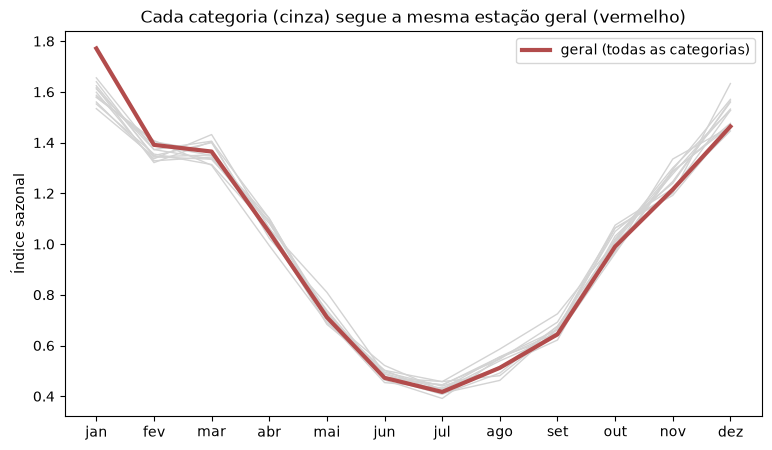

In [8]:
category_season = seasonal_index_by(complete, ["category_name"], DATE_COL)
category_season_pd = category_season.toPandas()
comparison = compare_to_global_season(category_season, global_season, "category_name").toPandas()
display(comparison[["category_name", "correlation_with_global", "max_abs_diff"]].sort_values("correlation_with_global"))

pivot_cat = category_season_pd.pivot(index="month_number", columns="category_name", values="seasonal_index")
global_pd = global_season.orderBy("month_number").toPandas()

fig, ax = plt.subplots(figsize=(9, 5))
for cat in pivot_cat.columns:
    ax.plot(pivot_cat.index, pivot_cat[cat], color="lightgray", linewidth=1)
ax.plot(global_pd["month_number"], global_pd["seasonal_index"], color=CORES[3], linewidth=3, label="geral (todas as categorias)")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES)
ax.set_ylabel("Índice sazonal")
ax.set_title("Cada categoria (cinza) segue a mesma estação geral (vermelho)")
ax.legend()
plt.show()

**O que o gráfico mostra:** as linhas cinzas (cada categoria) ficam praticamente coladas na linha vermelha (a estação geral) — a correlação de quase todas é muito alta. Só categorias com pouquíssimo volume se afastam um pouco, e isso é ruído por falta de dado, não uma estação diferente de verdade. **Um único calendário sazonal serve para o negócio inteiro**, não é preciso um por categoria.

## 6. Tendência

**Pergunta:** a demanda está crescendo, caindo ou estável?

Compara os últimos 12 meses com os 12 anteriores, por categoria e por local.

**Decisão que sai daqui:**
- Tendência forte: uma média de 12 meses fica "atrasada" (subestima em crescimento); o modelo precisa de uma feature de tendência.
- Tendência fraca: a média de 12 meses é uma boa referência de nível.

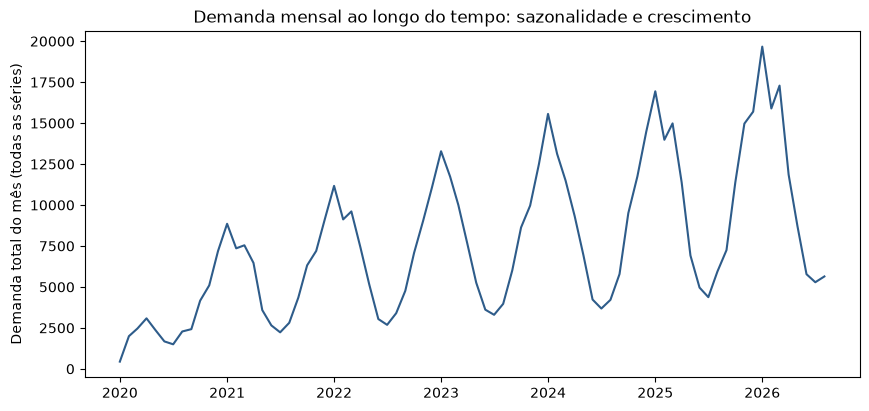

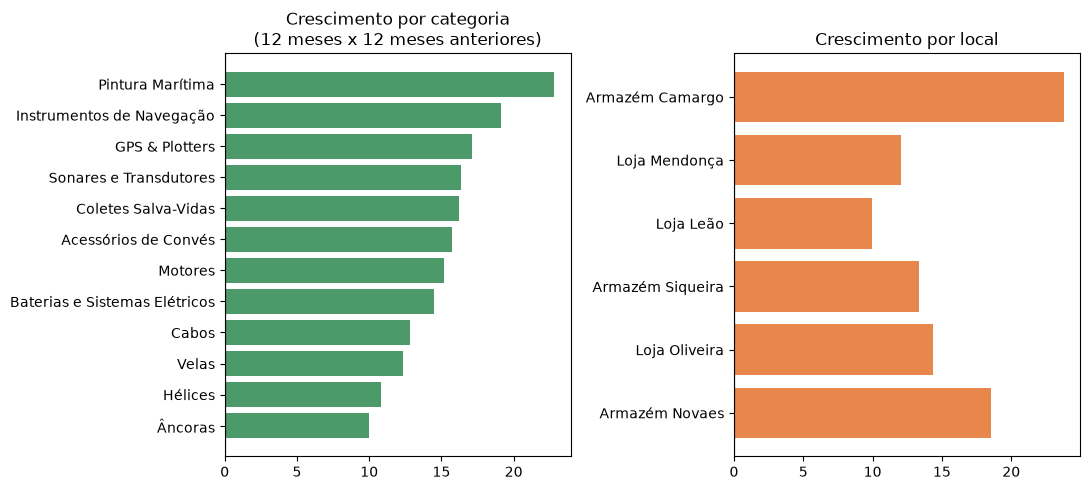

Crescimento total: 15.2%


In [9]:
ts = complete.groupBy(DATE_COL).agg(F.sum(F.col("demand_quantity").cast("double")).alias("demanda")).orderBy(DATE_COL).toPandas()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pd.to_datetime(ts[DATE_COL]), ts["demanda"], color=CORES[0])
ax.set_ylabel("Demanda total do mês (todas as séries)")
ax.set_title("Demanda mensal ao longo do tempo: sazonalidade e crescimento")
plt.show()

growth_total = year_over_year_growth(complete, REF_MONTH, date_col=DATE_COL).toPandas()
growth_cat = year_over_year_growth(complete, REF_MONTH, ["category_name"], date_col=DATE_COL).toPandas().sort_values("growth")
growth_loc = year_over_year_growth(complete, REF_MONTH, ["location_type", "location_name"], date_col=DATE_COL).toPandas()

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(growth_cat["category_name"], growth_cat["growth"] * 100, color=CORES[2])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Crescimento por categoria\n(12 meses x 12 meses anteriores)")

axes[1].barh(growth_loc["location_name"], growth_loc["growth"] * 100, color=CORES[1])
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Crescimento por local")

plt.tight_layout()
plt.show()

print(f"Crescimento total: {growth_total['growth'].iloc[0]:.1%}")

**O que os gráficos mostram:** a série de demanda total sobe visivelmente ao longo dos anos, além do sobe-e-desce da estação. O crescimento aparece em praticamente todas as categorias e locais, não só em alguns — ou seja, vem de **cada série vender mais**, não de mais séries entrando. Isso tem uma consequência direta: uma média de 12 meses olha para um período mais atrasado do que está sendo previsto e tende a **subestimar** a demanda futura. A engenharia de features precisa de uma feature de tendência.

## 7. Alcance dos produtos

**Pergunta:** cada produto vende em quantas lojas?

Um produto vendido em várias lojas permite **emprestar sinal**: a venda dele nas outras lojas ajuda a prever cada loja.

**Decisão que sai daqui:** o alcance vira feature.

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


,locations_selling_12m,n_products,volume_12m,share_products,share_volume_12m
0,4,3,330.0,0.0030,0.0024
1,5,82,9625.0,0.0813,0.0690
2,6,924,129468.0,0.9158,0.9286


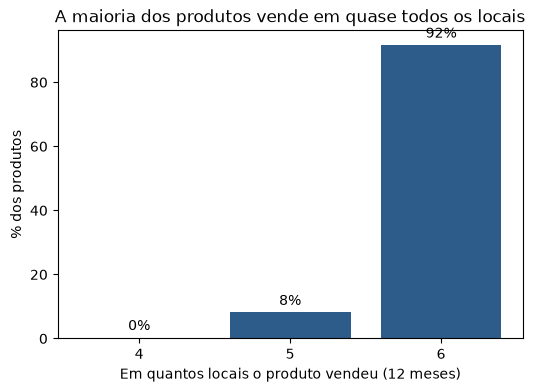

In [10]:
reach = product_reach(segmented).toPandas()
display(reach)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(reach["locations_selling_12m"].astype(str), reach["share_products"] * 100, color=CORES[0])
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.set_xlabel("Em quantos locais o produto vendeu (12 meses)")
ax.set_ylabel("% dos produtos")
ax.set_title("A maioria dos produtos vende em quase todos os locais")
plt.show()

**O que o gráfico mostra:** a grande maioria dos produtos vende em todos ou quase todos os locais, então a venda do mesmo produto nos outros locais está disponível como sinal para a maior parte do volume. O notebook 03 testa se essa informação ajuda mais do que a média da categoria no local.

## 8. Resumo — grupos que seguem para a Etapa 2

Cruzamento final: fase de vida × classe ABC, com o volume de cada grupo.

In [11]:
phase_x_abc = segment_summary(segmented, ["life_phase", "abc_class"]).toPandas()

display(phase_x_abc.pivot(index="life_phase", columns="abc_class", values="n_series").fillna(0).astype(int))
phase_x_abc.pivot(index="life_phase", columns="abc_class", values="share_volume_12m").fillna(0)

C:\indicium_ai\athena\lh_nautical\.venv\Lib\site-packages\pyspark\sql\connect\expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


abc_class,A,B,C,sem_venda
life_phase,,,,
ativa,3593,1378,995,0
parada,0,0,0,88


abc_class,A,B,C,sem_venda
life_phase,,,,
ativa,0.8,0.15,0.05,0.0
parada,0.0,0.00,0.00,0.0


**O que significa:** o universo da Etapa 2 são **todas as séries produto × loja**, avaliadas juntas e quebradas por **frequência de venda** (a divisão que mais diferencia as séries) e por categoria.

## Conclusão

**Em uma frase, para quem não trabalha com dados:** o negócio é bastante uniforme — nenhum produto "estrela", nenhum produto "moribundo", a mesma época de alta venda em todas as categorias — então dá para tratar todas as séries produto × loja com a mesma régua, em vez de criar uma regra diferente para cada tipo de produto.

| Pergunta | Resposta | Decisão para as próximas etapas |
|---|---|---|
| O volume é concentrado? | Não: é preciso boa parte das séries para chegar a 80% do volume | Avaliação sem ponderar por volume |
| Com que frequência as séries vendem? | Poucos meses em 12; a maioria em frequência baixa ou média | Quebrar o erro por frequência; esperar médias curtas ruidosas |
| Há séries novas ou descontinuadas? | Não: quase nenhuma nova, e a maioria das "paradas" volta a vender | Todas as séries no mesmo modelo, sem regras separadas |
| A estação muda por categoria? | Não: todas seguem de perto a estação geral | Índice sazonal geral |
| Há tendência? | Sim: demanda crescendo em todas as categorias e locais | Feature de tendência |
| Dá para emprestar sinal entre locais? | Sim: quase todo produto vende em quase todos os locais | Venda do produto nos outros locais como feature candidata — testada no notebook 03 |

**Observação sobre os dados:** grade quase completa, locais com volume parecido, crescimento e estação iguais em todas as categorias. É um padrão bem regular, típico de dados simulados. Não muda as decisões, mas significa que o ganho de features por segmento (categoria, local) deve ser pequeno, e o que mais importa é tendência, estação e o sinal agregado.